# Country Development Clustering

Grouping **167 countries** into development levels using socio-economic and health indicators. Such groups can help a humanitarian organization decide which countries need support most urgently.

**Methods:** K-Means (elbow + silhouette), Hierarchical Agglomerative Clustering (Ward), PCA, and K-Means on PCA-reduced data.

## Dataset
File: `data/country_data.csv`


| Variable | Description | Type |
|----------|-------------|------|
| `country` | Name of the country | Categorical (identifier) |
| `child_mort` | Death of children under 5 years of age per 1000 live births | Continuous |
| `exports` | Exports of goods and services per capita (% of GDP) | Continuous |
| `health` | Total health spending per capita (% of GDP) | Continuous |
| `imports` | Imports of goods and services per capita (% of GDP) | Continuous |
| `income` | Net income per person | Continuous |
| `inflation` | Annual growth rate of Total GDP (%) | Continuous |
| `life_expec` | Average number of years a newborn child would live | Continuous |
| `total_fer` | Number of children that would be born to each woman | Continuous |
| `gdpp` | GDP per capita | Continuous |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

## 1. Exploration
Correlation heatmaps and scatter plots for strongly related variable pairs.

<Axes: >

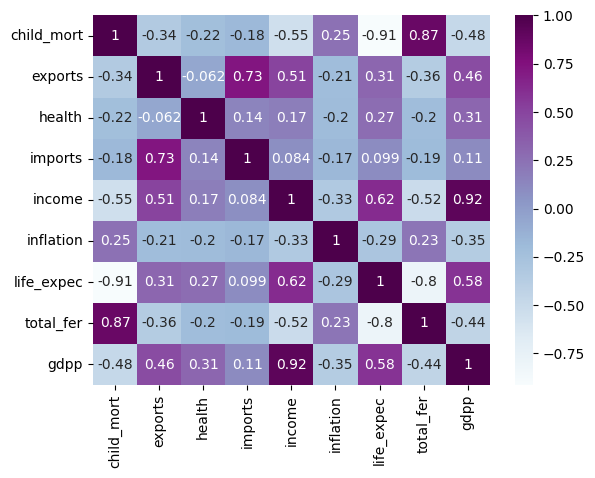

In [2]:
df_country=pd.read_csv('data/country_data.csv')
df_country

variables=df_country.drop(columns='country')
corr_country=variables.corr()
sns.heatmap(corr_country, annot=True, cmap='BuPu')

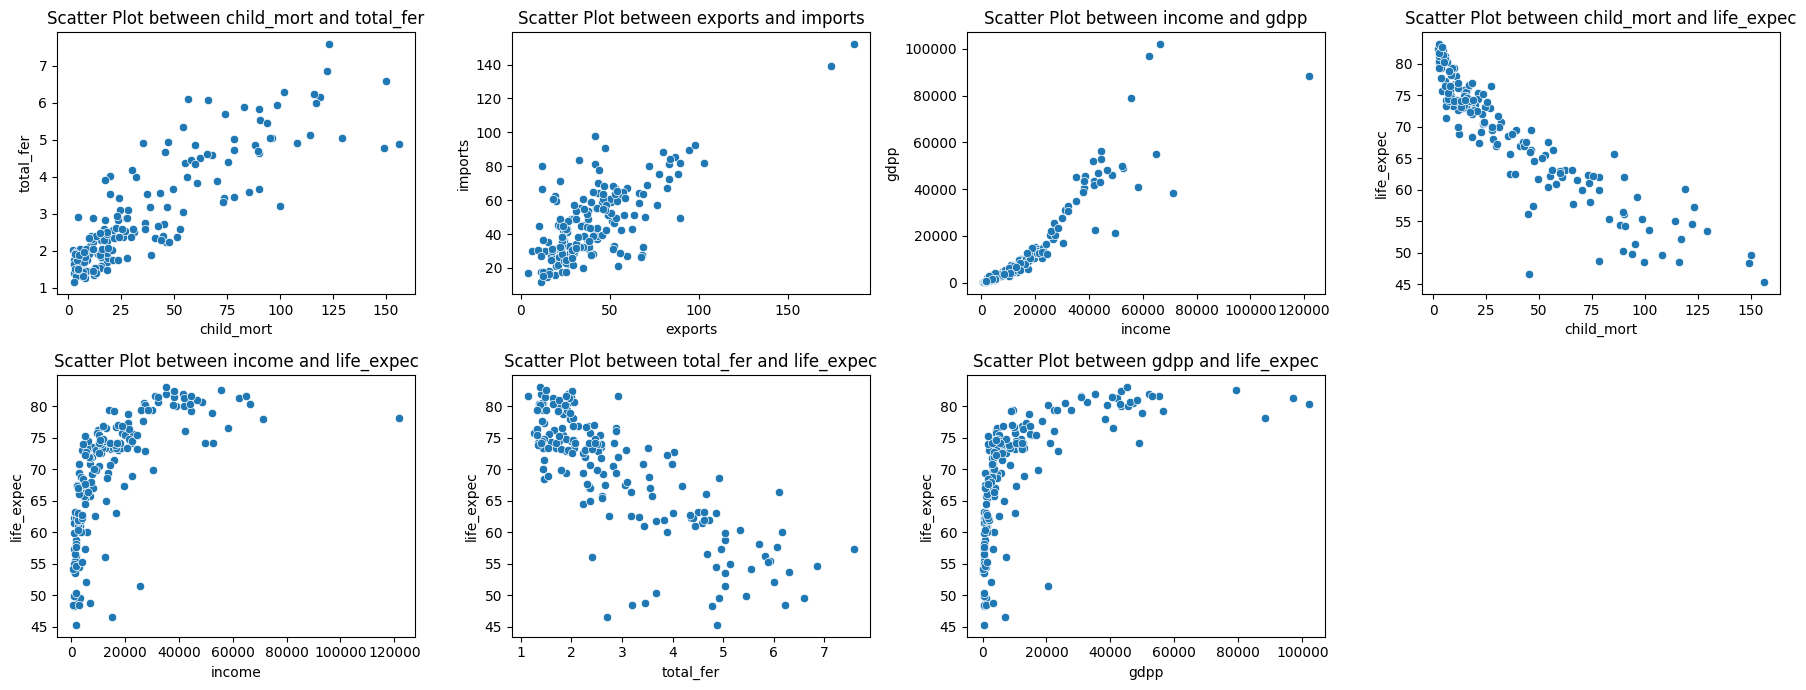

In [3]:
pairs=[
    ('child_mort','total_fer'),
    ('exports','imports'),
    ('income','gdpp'),
    ('child_mort','life_expec'),
    ('income','life_expec'),
    ('total_fer','life_expec'),
    ('gdpp','life_expec')
]
plt.figure(figsize=(18, 7))

for i, pair in enumerate(pairs):
    plt.subplot(2, 4, i+1)
    sns.scatterplot(x=pair[0], y=pair[1], data=df_country)
    plt.title(f'Scatter Plot between {pair[0]} and {pair[1]}')

plt.tight_layout()
plt.show()   

<Axes: >

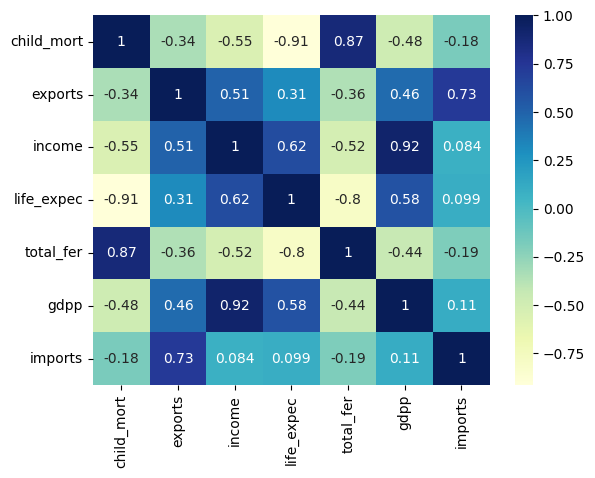

In [4]:
selected_features=['child_mort', 'exports', 'income', 'life_expec', 'total_fer', 'gdpp','imports']

corr_selected=df_country[selected_features].corr()
sns.heatmap(corr_selected, annot=True, cmap='YlGnBu')

**Which variables are highly correlated?**

The highest correlation is between `gdpp` and `income`. Both show similar information about a country's economic level, so they represent economic development in a similar way.

**Are there visible clusters in the scatter plots?**

Yes. Countries are grouped into different areas instead of being randomly spread. Some countries have high income and high life expectancy with low child mortality, while others show low income and high child mortality, so countries form natural groups based on economic and health variables.

## 2. Preprocessing
Missing values, outlier decision and scaling.

In [5]:
df_country

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...,...
172,Venezuela,15.0,25.4,4.80,17.6,17100,26.10,74.2,2.47,12500
173,Vietnam,23.5,72.0,6.00,80.2,5030,9.09,75.2,1.75,1740
174,Yemen,60.0,30.7,5.18,32.0,3770,11.20,62.7,4.35,1310
175,Zambia,83.1,38.0,5.01,36.0,3810,8.68,55.3,5.88,1500


In [6]:
df_country.isnull().sum()

#There is no any missing value in the dataset.

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

**Outliers were kept.** They represent real countries with extreme economic and health conditions, not measurement errors. Removing them would hide important differences between developed and developing countries. Log transformation was not applied, to keep the original values and see these differences clearly.

**Scaling:** K-Means uses distances, so all features are standardized. Otherwise large-valued features such as `income` and `gdpp` would dominate the clustering.

In [7]:
#standardize 
scaler_countrydf = StandardScaler()
df_country_scaled = scaler_countrydf.fit_transform(df_country.drop(columns='country'))
df_country_scaled = pd.DataFrame(df_country_scaled,columns=df_country.drop(columns='country').columns)
df_country_scaled

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.510144,-1.220811,0.368758,-0.102252,-0.830184,0.692907,-1.434290,1.972457,-0.656082
1,-0.547351,-0.511888,-0.022149,0.066766,-0.356403,-0.221221,0.736456,-0.867341,-0.465818
2,-0.248232,-0.102289,-0.925411,-0.718939,-0.187278,1.922824,0.758056,-0.022893,-0.445915
3,2.315250,0.839003,-1.426379,-0.193613,-0.585891,3.086258,-1.013100,2.203999,-0.495942
4,-0.723468,0.177342,-0.219501,0.537275,0.165780,-0.784471,0.790455,-0.540458,-0.029561
...,...,...,...,...,...,...,...,...,...
172,-0.592079,-0.614288,-0.686312,-1.349331,0.051891,3.769546,0.509662,-0.308915,-0.013423
173,-0.354461,1.221033,-0.230886,1.510271,-0.635433,0.628272,0.617659,-0.799240,-0.592231
174,0.665900,-0.405550,-0.542094,-0.691531,-0.707183,1.017930,-0.732307,0.971377,-0.615361
175,1.311662,-0.118042,-0.606613,-0.508809,-0.704905,0.552556,-1.531487,2.013317,-0.605141


## 3. K-Means Clustering
Testing k = 2…10 with the elbow method and silhouette score, then fitting the chosen k and visualizing it with the first two principal components.

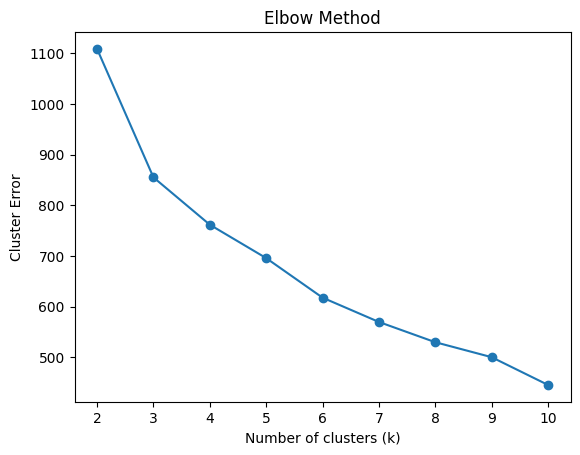

In [8]:
#1. Use the **Elbow Method** to determine the optimal number of clusters (test k = 2 to 10)
cluster_error=[]
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_country_scaled)
    cluster_error.append(kmeans.inertia_)

plt.plot(range(2, 11), cluster_error, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Cluster Error")
plt.title("Elbow Method")
plt.show()

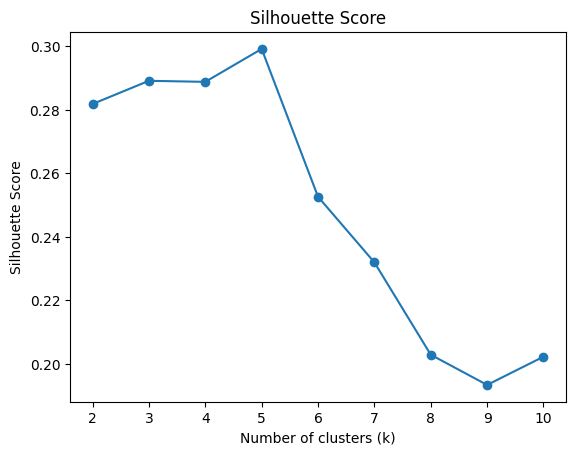

In [9]:
#2. Also calculate the **Silhouette Score** for each k value
from sklearn.metrics import silhouette_score
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(df_country_scaled)
    silhouette_avg = silhouette_score(df_country_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

silhouette_scores
#silhoutte formülü= (B-A)/max(A,B)
#B = en yakın küme ile olan ortalama uzaklık
#A = kendi kümesi içindeki ortalama uzaklık
#k arttıkça bu skor azalıyor

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

**Choosing k**

In the Elbow Method graph, there is no very sharp elbow point, but the curve starts to flatten around k = 5. After this value, the decrease in error becomes smaller.
In the Silhouette Score graph, the highest score is clearly at k = 5. This means the clusters are more separated and better formed at this value.

Even though the Elbow Method is not very clear, the Silhouette Score strongly supports k = 5, so we selected this value.

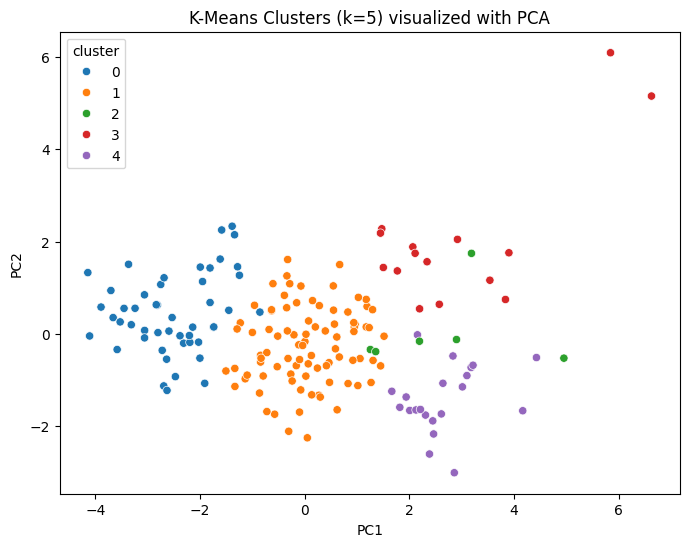

In [10]:
kmeans_final = KMeans(n_clusters=5, random_state=42)
labels_cluster = kmeans_final.fit_predict(df_country_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_country_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['cluster'] = labels_cluster
df_pca['country'] = df_country['country'].values

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='cluster', palette='tab10')
plt.title('K-Means Clusters (k=5) visualized with PCA')
plt.show()

In [11]:
df_country['KMeans_Cluster']=labels_cluster

**Do the elbow and silhouette methods agree?**

I chose k = 5 as the number of clusters. The Silhouette Score is highest at k = 5, which means the clusters are clear and well separated. The Elbow Method does not show a very clear elbow point, but after k = 4 or k = 5, the error decreases more slowly. Even though the Elbow Method is not very clear, the Silhouette Score strongly supports k = 5, so this value was selected.

**Limitation of the 2D view**

Using only 2D visualization is limited because the dataset has 9 features. When we reduce the data to 2 dimensions, some information is lost. Because of this, some points may look close or mixed in the plot, even if they are different in the original data. Therefore, the 2D plot is only for visualization, not for full analysis.

**Example countries from each cluster:** 

In [12]:
df_clusters = df_country.copy()
df_clusters['cluster'] = labels_cluster

df_country_cluster_pair=pd.DataFrame({'country':df_clusters['country'],'cluster':df_clusters['cluster']})
df_country_cluster_pair

cluster_country_dict = {}

for cluster_num in range(5):
    cluster_country_dict[cluster_num] = (df_country_cluster_pair[df_country_cluster_pair['cluster'] == cluster_num]['country'].head(5).tolist())

cluster_country_dict

{0: ['Afghanistan', 'Angola', 'Benin', 'Botswana', 'Burkina Faso'],
 1: ['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia'],
 2: ['Brunei', 'Kuwait', 'Oman', 'Qatar', 'Saudi Arabia'],
 3: ['Belgium', 'Czech Republic', 'Estonia', 'Hungary', 'Ireland'],
 4: ['Australia', 'Austria', 'Canada', 'Cyprus', 'Denmark']}

**Does the grouping make sense?**

Yes, the grouping makes intuitive sense. Countries in the same cluster have similar economic and social values, such as income, GDP per capita, life expectancy, and child mortality. For example, countries with low income and high child mortality are grouped together, while rich countries with high income and long life expectancy are in another cluster. This shows that the clustering separates developed and developing countries in a logical way.

## 4. Hierarchical Agglomerative Clustering
Ward linkage, dendrogram, choosing a cut height, and comparison with K-Means.

In [13]:
#1. Apply Hierarchical Agglomerative Clustering (HAC) to your scaled data
hac=AgglomerativeClustering(n_clusters=5, linkage='ward')
labels_hac = hac.fit_predict(df_country_scaled)

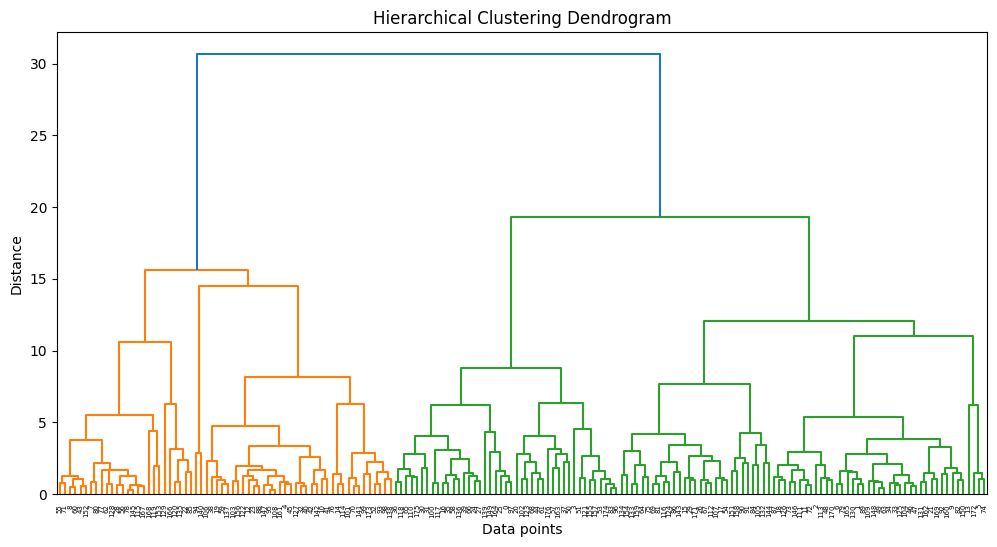

In [14]:
#2. Create a **dendrogram** to visualize the hierarchical structure
linked=linkage(df_country_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data points")
plt.ylabel("Distance")
plt.show()

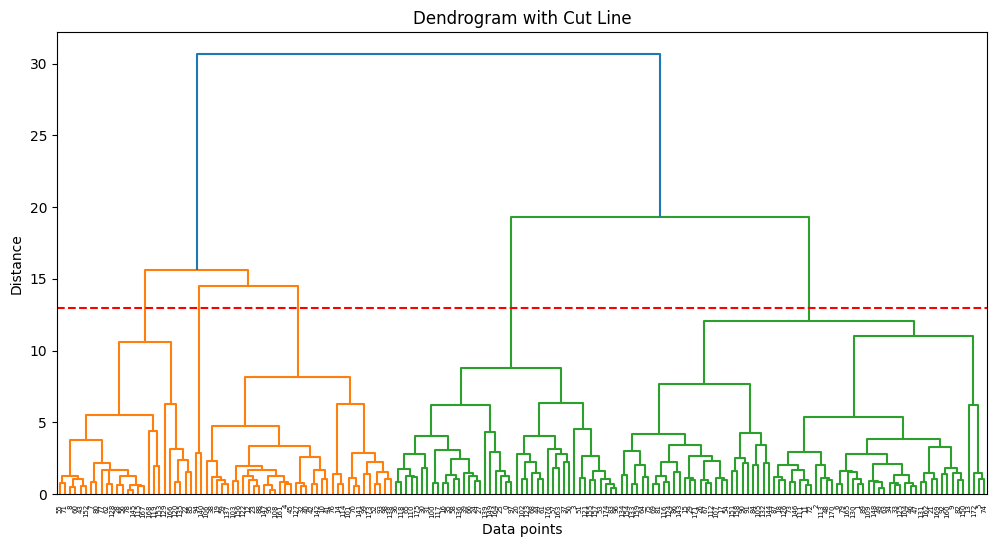

In [15]:
#3. Based on the dendrogram, determine the optimal number of clusters by identifying where to "cut" the tree
#4. Cut the dendrogram at your chosen level and obtain cluster labels
plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.axhline(y=13, color='red', linestyle='--')
plt.title("Dendrogram with Cut Line")
plt.xlabel("Data points")
plt.ylabel("Distance")
plt.show()

In [16]:
df_country['hac_cluster'] = labels_hac

In the dendrogram, the long vertical line shows that some groups are far from each other and only merge at a high distance. Because of this, I do not merge them and keep them separate. When I cut the dendrogram at this level, I obtain 5 clusters. Using this cut, cluster labels are assigned to each data point.

In [17]:
#5. Compare the resulting clusters with your K-Means results
pd.crosstab(df_country['KMeans_Cluster'], df_country['hac_cluster'], rownames=['KMeans'], colnames=['HAC'])

HAC,0,1,2,3,4
KMeans,,,,,
0,6,0,42,0,0
1,64,0,1,22,0
2,0,6,0,0,0
3,0,0,0,13,2
4,0,20,0,1,0


When I compare K-Means and hierarchical clustering, I see that the results are similar. Many data points are placed in the same clusters by both methods. Some clusters are divided into smaller groups by hierarchical clustering. This shows that both methods find similar patterns, but hierarchical clustering gives more detail.

**Looking at the dendrogram, at what height/distance would you cut to get meaningful clusters? Why?**

I would cut the dendrogram at a distance of around 13. At this height, there is a clear long vertical gap, which shows that the groups are far from each other. Cutting at this level gives 5 meaningful clusters and shows the structure of the data clearly.

**Does the hierarchical structure suggest the same number of clusters as K-Means?**

Yes, the hierarchical structure suggests a similar number of clusters as K-Means. Both methods indicate that 5 clusters is a reasonable choice for grouping the data.

**How similar are the HAC clusters to the K-Means clusters? Do the same countries tend to be grouped together?**

HAC clusters are similar to K-Means clusters. In both methods, most of the same countries are grouped together. With hierarchical clustering, some K-Means clusters are broken down into smaller groups, but the overall structure remains consistent.

## 5. Dimensionality Reduction with PCA
How many components are needed to keep 80% and 95% of the variance?

In [18]:
pca_all=PCA()  # keep all components
X_pca_all = pca_all.fit_transform(df_country_scaled)

In [19]:
cumulative_variance = np.cumsum(pca_all.explained_variance_ratio_)

comp_80=np.argmax(cumulative_variance >= 0.80) + 1
comp_90=np.argmax(cumulative_variance >= 0.95) + 1

print(f'Number of components to explain at least 80% variance: {comp_80}')
print(f'Number of components to explain at least 95% variance: {comp_90}')

Number of components to explain at least 80% variance: 4
Number of components to explain at least 95% variance: 5


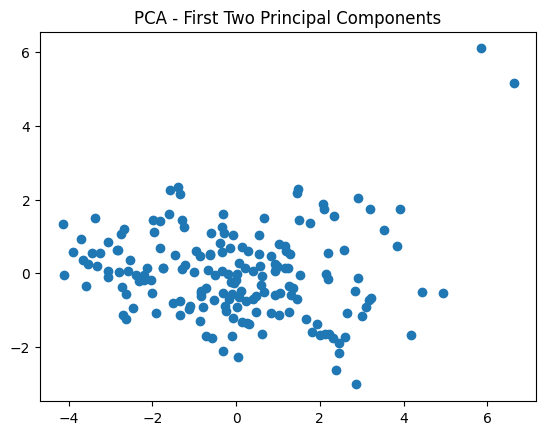

In [20]:
pca_first_two=PCA(n_components=2)
X_pca_first_two = pca_first_two.fit_transform(df_country_scaled)

plt.title('PCA - First Two Principal Components')
plt.scatter(X_pca_first_two[:, 0], X_pca_first_two[:, 1])
plt.show()

**Natural groupings in 2D?**

In the PCA plot, some groups appear, but they are not very clear. This is because only two components are shown, and some information is lost.

## 6. K-Means on PCA-Reduced Data
Using 4 principal components, repeating the elbow and silhouette analysis.

In [21]:
pca_kmeans=PCA(n_components=4)  # 4 components explain at least 80% of the variance (see 5.1)
X_pca_kmeans = pca_kmeans.fit_transform(df_country_scaled)

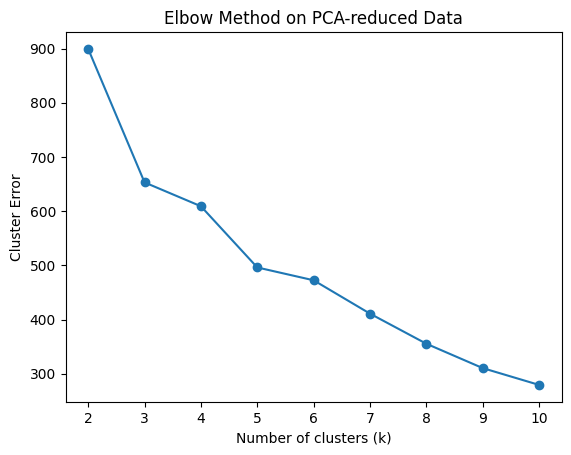

In [22]:
#apply elbow
cluster_error2=[]
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_pca_kmeans)
    cluster_error2.append(kmeans.inertia_)

plt.plot(range(2, 11), cluster_error2, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Cluster Error")
plt.title("Elbow Method on PCA-reduced Data")
plt.show()

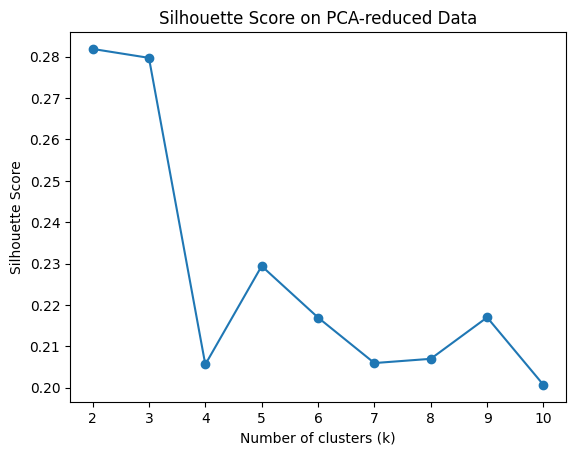

In [23]:
#apply silhouette score
silhouette_scores2 = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_pca_kmeans)
    silhouette_avg2 = silhouette_score(df_country_scaled, cluster_labels)
    silhouette_scores2.append(silhouette_avg2)

silhouette_scores2


plt.plot(range(2, 11), silhouette_scores2, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score on PCA-reduced Data")
plt.show()

When I look at the Elbow Method, I see that the decrease in error starts to slow down around k = 4–5. Even though the Silhouette Score is higher for very small k values, these cases are too simple and do not represent the data well. Among the larger values, k = 5 gives a better balance between separation and structure. Therefore, I choose k = 5 as the optimal number of clusters.

In [24]:
kmeans_pca=KMeans(n_clusters=5, random_state=42)
labels_kmeans_pca=kmeans_pca.fit_predict(X_pca_kmeans)

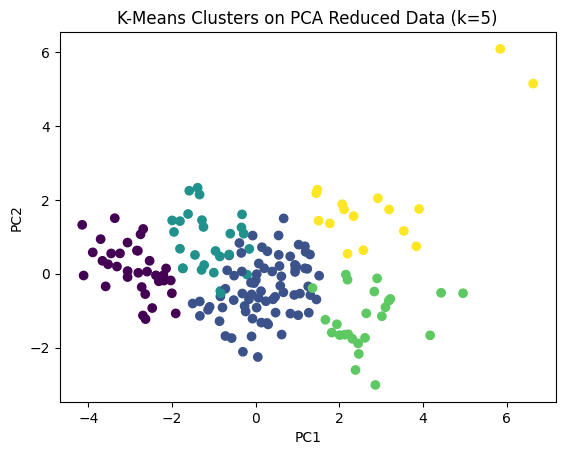

In [25]:
plt.scatter(X_pca_kmeans[:, 0],X_pca_kmeans[:, 1],c=labels_kmeans_pca)

plt.title("K-Means Clusters on PCA Reduced Data (k=5)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

**Is the optimal k the same as before PCA? If different, why might this be?**

Yes, the optimal value of k is the same as before PCA. Both before and after applying PCA, the analysis suggests k = 5 as the optimal number of clusters.

**Are the clusters more or less separable in the PCA space?**

Compared to before, the clusters look more separated in the PCA space, but there is still some overlap. PCA helps visualization, but not all clusters are clearly separated in 2D.

## Summary

- **k = 5** clusters, supported by the silhouette score (highest at k = 5) and consistent with the elbow curve.
- Hierarchical clustering (Ward) also gives 5 clusters with very similar groupings; it splits some K-Means groups more finely.
- **4 principal components** keep ≥ 80% of the variance and **5** keep ≥ 95%. K-Means on the PCA-reduced data again suggests k = 5.
- The clusters separate low-income / high child-mortality countries from high-income / high life-expectancy countries, with intermediate groups in between.